# 5d — Combined Hazard Criticality, Costa Rica

## Purpose

Final step of the CR workflow: combine every upstream result into one per-road
**combined hazard-criticality** index over the 5,012 physical roads, classify it, map it, cross it
with the MIDEPLAN IDS development quintiles, and export it.

Three sub-indices are combined multiplicatively:

| | Sub-index | Source | Built by |
|---|---|---|---|
| **H** | Hazard exposure | 5a's `hazard_score` — mean of three band-normalised ordinals (flood exceedance frequency, LHASA landslide class, Rx1month return level) | notebook 5a |
| **T** | National travel disruption | `phl`, `thl`, `pkl`, `tkl` from the SPOF percolation | notebook 2 |
| **A** | Local health accessibility | flood-scenario delay to hospitals and EBAIS | notebooks 5b → 5c |

`CC = norm(H) × (norm(T) + norm(A))`

> ### ⚠ This is not risk
>
> Inherited from 5a and 5b. Roads are screened *one at a time* against hazard **footprints**. There
> is no fragility curve, no closure probability, no duration and no expected annual loss. "High
> criticality" means "this road is both hazard-exposed and costly to lose", never "this road will
> fail".

> ### ⚠ It is "hazard", not "climate" — the word is dropped deliberately
>
> The Serbia original calls this *climate criticality* and defaults to a climate-change hazard
> subset (projected rainfall change, projected pavement heat, landslide). **Costa Rica has no
> climate-projection data at all**, and CR's three hazards are all present-day: an RP-based flood
> frequency, a static landslide susceptibility, and an *observed* rainfall return level. Calling the
> result "climate" would claim a forward-looking content it does not have. The filename keeps its
> `5d_Combined_Climate_Criticality_CR` stem for pipeline continuity only.

> ### ⚠ A is not an independent third channel — it is flood-conditional
>
> A is non-zero only on roads that a flood scenario removed, and a road enters a scenario only if
> `flood_depth_rp100 > 0.25 m`. So A sits beside a hazard index that already contains flood.
> Measured below: Spearman(A, flood depth) ≈ 0.92 and Spearman(H, A) ≈ 0.40, against **0.025** in
> Serbia's own run — the dependence is introduced by the CR transposition, because CR must put flood
> in H where Serbia's default did not. Section 6 also shows that dropping A entirely barely moves
> the ranking. **Read CC as an H×T ranking that A adjusts at the margin, not as three co-equal
> pillars.**

> ### ⚠ A measures the isolation penalty as much as travel time
>
> 5c's `travel_time_impact` is the unweighted mean positive delay over affected origins, *including*
> origins cut off entirely and charged 5b's derived **7 h** isolation penalty — 31.8 % of affected
> origin-rows. It is also a **basin** mean replicated onto every road in that basin, so 326 roads
> carry ~45 distinct values. Never quote it as "this road adds N minutes".
>
> Note this is the **opposite** of Serbia's convention, which replaces an unreachable origin's
> infinite delay with **1 hour** — making total isolation score *milder* than a moderate delay.
> Serbia's A is deflated by isolation; CR's is inflated by it. The two are not the same quantity.

## Inputs

| File | Description |
|------|-------------|
| `intermediate_results/gpkg/travel_disruptions/main_network_hazard_criticality.gpkg` (layer `physical`) | 5,012 physical roads × 45 cols — supplies **both** H and T, already joined by 5a |
| `intermediate_results/parquet/flood_scenarios/road_impacts.parquet` | 1,512 rows (378 roads × 2 origin sets × 2 sectors) from 5c — supplies **A** |
| `intermediate_results/gpkg/travel_disruptions/socioeconomic_criticality.gpkg` (layer `physical_by_quintile`) | 5,012 roads × 95 cols from 2b — the IDS quintile attribution |
| `input_files/ids_2023_distrital/ids_2023_distrito.shp`, `input_files/CENTROS_POBLACION/centros_poblados_localidades.shp` | population per IDS quintile, used only as the denominator in §9 |

All three road tables are keyed 1:1 on `physical_edge_id`, so every join here is an attribute merge.
The Serbia original assembles the same thing with nine spatial joins because its sources share no
key; that heuristic is gone.

## Outputs

| File | Description |
|------|-------------|
| `intermediate_results/gpkg/travel_disruptions/combined_hazard_criticality.gpkg` (layer `criticality`) | all 5,012 roads, EPSG:8908, scored and classified — nothing filtered |
| `intermediate_results/excel/Combined_Hazard_Criticality_CR.xlsx` | formatted workbook: Overview, Hazard Exposure, Travel Disruption, Local Accessibility, IDS Equity, Metric Descriptions |
| `figures/hazard_criticality_HTA_3panel_CR.png` | the three sub-indices side by side |
| `figures/combined_hazard_criticality_CR.png` | the combined index |
| `figures/hazard_criticality_metric_support_CR.png` | what each convex score was ranked over |
| `figures/hazard_criticality_variants_CR.png` | CC under each scoring variant |
| `figures/hazard_criticality_by_IDS_quintile_CR.png` | the equity crossing |

## Processing steps

1. **Load** the three per-road tables; assert 1:1 keys and EPSG:8908.
2. **Attach A** from 5c: select one `origin_set`, pivot wide on sector, keep `a_evaluated` so a
   *measured* zero stays distinguishable from a road never evaluated.
3. **Report metric support** *before* scoring — the share of the network each metric is ranked over.
4. **Score**: H taken directly; T and A quintile-ranked and convex-mapped, summed, min-max
   normalised; combine multiplicatively; classify into tiers.
5. **Sensitivity**: CC with A dropped, unnormalised, and on the `wp` origin set.
6. **Maps**, **IDS quintile crossing**, **statistics by road class**.
7. **Export** GeoPackage + workbook, then reconcile row counts.

## Method decisions

Recorded in `MD/5d_Combined_Climate_Criticality_CR_plan.md` §5. The five that change what the index
measures:

- **D1/D4** — H is 5a's `hazard_score`, used directly. The hazard metrics are **not** re-quintiled
  in this notebook; 5a's per-layer bands are the commensurability mechanism. T and A *are*
  quintiled, so H is scored by a different mechanism from T and A — see §4.
- **D3a** — A carries both sectors, hospitals and EBAIS.
- **D3b** — the `loc` (493 localities) arm feeds A; `wp` is reported as a variant. `loc` is the only
  arm carrying `CÓDIGO_DTA`, which §9's quintile crossing needs. Reversible via `ORIGIN_SET`.
- **D5** — normalised: `norm(H) × (norm(T) + norm(A))`.
- **D7** — the H/A circularity is accepted and explained (§7), not engineered away.


## 1. Imports and configuration

In [1]:

from pathlib import Path
import warnings

import geopandas as gpd
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=RuntimeWarning)

In [2]:

# ---- Paths ---------------------------------------------------------------
BASE_DIR = Path.cwd().parent              # notebook lives in /notebooks
figure_path = BASE_DIR / "figures"
intermediate_path = BASE_DIR / "intermediate_results"

# Shared CR map style: extent, basemap, outline, cities, legend (src/map_style_cr.py)
import sys
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))
from src.map_style_cr import add_cr_legend, style_cr_map
input_path = BASE_DIR / "input_files"

disruption_dir = intermediate_path / "gpkg" / "travel_disruptions"
hazard_criticality_gpkg = disruption_dir / "main_network_hazard_criticality.gpkg"
socioeconomic_gpkg = disruption_dir / "socioeconomic_criticality.gpkg"
road_impacts_parquet = intermediate_path / "parquet" / "flood_scenarios" / "road_impacts.parquet"
ids_shp = input_path / "ids_2023_distrital" / "ids_2023_distrito.shp"
localities_shp = input_path / "CENTROS_POBLACION" / "centros_poblados_localidades.shp"

out_gpkg = disruption_dir / "combined_hazard_criticality.gpkg"
# The workbook is the one non-GeoPackage output (plan D8). It lives under
# intermediate_results/ so it is gitignored like every other data artefact; CR has no
# results/ directory and creating a tracked one would commit a binary.
excel_dir = intermediate_path / "excel"
out_xlsx = excel_dir / "Combined_Hazard_Criticality_CR.xlsx"

figure_path.mkdir(parents=True, exist_ok=True)
excel_dir.mkdir(parents=True, exist_ok=True)

# ---- Constants -----------------------------------------------------------
WORKING_EPSG = 8908          # CR-SIRGAS / CRTM05, metres
DPI = 300

ORIGIN_SET = "loc"           # plan D3b; "wp" is the reported variant in section 6
TRAVEL_METRICS = ["phl", "thl", "pkl", "tkl"]                 # T, ceiling 40
ACCESS_METRICS = ["hospital_delay", "ebais_delay"]            # A, ceiling 20 (D3a)
SECTOR_TO_METRIC = {"hospitals": "hospital_delay", "ebais": "ebais_delay"}

# Convex score per quintile. Q5 counts 20x Q1: the index is deliberately top-heavy,
# because the policy question is which roads are worst, not how the middle is ordered.
# (Serbia's docstring says Q1 -> 0 while its code says 0.5; the code is what ran, and
# what is reproduced here.)
CONVEX_MAP = {0: 0.0, 1: 0.5, 2: 1.0, 3: 2.0, 4: 5.0, 5: 10.0}

CLASS_ORDER = ["No criticality", "Very Low", "Low", "Medium", "High", "Very High"]
CLASS_COLORS = ["#e8e8e8", "#fee5d9", "#fcae91", "#fb6a4a", "#de2d26", "#a50f15"]
CLASS_WIDTHS = [0.3, 0.5, 0.8, 1.2, 1.6, 2.0]

# IDS quintile encoding, identical to notebook 2b so the two are readable together.
QCOLS = ["q1", "q2", "q3", "q4", "q5"]
QNAMES = ["Q-I (lowest IDS)", "Q-II", "Q-III", "Q-IV", "Q-V (highest IDS)"]
QCOLORS = ["#d7191c", "#fdae61", "#ffffbf", "#abdda4", "#2b83ba"]
QUINTIL_ORDER = ["I", "II", "III", "IV", "V"]

for label, p in [("hazard criticality (5a)", hazard_criticality_gpkg),
                 ("road impacts (5c)", road_impacts_parquet),
                 ("socioeconomic (2b)", socioeconomic_gpkg)]:
    print(f"{label:26s} {p.name:45s} exists: {p.exists()}")
print(f"\norigin set for A          : {ORIGIN_SET}")
print(f"output GeoPackage         : {out_gpkg.relative_to(BASE_DIR)}")
print(f"output workbook           : {out_xlsx.relative_to(BASE_DIR)}")

hazard criticality (5a)    main_network_hazard_criticality.gpkg          exists: True
road impacts (5c)          road_impacts.parquet                          exists: True
socioeconomic (2b)         socioeconomic_criticality.gpkg                exists: True

origin set for A          : loc
output GeoPackage         : intermediate_results/gpkg/travel_disruptions/combined_hazard_criticality.gpkg
output workbook           : intermediate_results/excel/Combined_Hazard_Criticality_CR.xlsx


## 2. Load the three per-road tables

One read of 5a's `physical` layer supplies H *and* T, because 5a already joined the hazard table to
the criticality results. Keys are asserted 1:1 rather than assumed.

In [3]:

gdf = gpd.read_file(hazard_criticality_gpkg, layer="physical")
socio = gpd.read_file(socioeconomic_gpkg, layer="physical_by_quintile")
impacts = pd.read_parquet(road_impacts_parquet)

print(f"5a hazard criticality : {len(gdf):,} roads x {len(gdf.columns)} cols   CRS {gdf.crs.to_epsg()}")
print(f"2b socioeconomic      : {len(socio):,} roads x {len(socio.columns)} cols   CRS {socio.crs.to_epsg()}")
print(f"5c road impacts       : {len(impacts):,} rows")
print(f"                        origin sets {sorted(impacts['origin_set'].unique())}, "
      f"sectors {sorted(impacts['sector'].unique())}")

assert gdf.crs.to_epsg() == WORKING_EPSG, f"unexpected CRS {gdf.crs}"
assert gdf["physical_edge_id"].is_unique, "physical_edge_id is not unique"
assert set(gdf["physical_edge_id"]) == set(socio["physical_edge_id"]), "2b key set differs"
assert set(impacts["physical_edge_id"]) <= set(gdf["physical_edge_id"]), "5c has unknown roads"

TOTAL_ROADS = len(gdf)
NETWORK_KM = gdf["road_length"].sum()
print(f"\nnetwork: {TOTAL_ROADS:,} physical roads, {NETWORK_KM:,.0f} km")
print("keys verified 1:1 on physical_edge_id -- every join below is an attribute merge")

# No deduplication step. Serbia collapses its network to one row per `oznaka_deo` inside 5d;
# CR's collapse to physical roads happened in notebook 2, and repeating it here would
# double-aggregate. Serbia also drops 801 of 3,154 rows for a null section id; CR loses none.

5a hazard criticality : 5,012 roads x 45 cols   CRS 8908
2b socioeconomic      : 5,012 roads x 95 cols   CRS 8908
5c road impacts       : 1,512 rows
                        origin sets ['loc', 'wp'], sectors ['ebais', 'hospitals']

network: 5,012 physical roads, 14,811 km
keys verified 1:1 on physical_edge_id -- every join below is an attribute merge


## 3. Attach 5c's accessibility layer as A

5c emits one **long** table (road × origin set × sector). Serbia instead emits seven *wide*
`*_impacts.parquet` files under `parquet/local_accessibility/`, which is why the Serbia notebook's
accessibility paths cannot be repointed — the shape differs too.

Two things 5c was careful about and that must survive here:

- a road measured at **zero** impact is not a road that was **never evaluated**. 5c keeps the 52
  measured zeros explicitly; `a_evaluated` carries that distinction into the output, because both
  end up as 0.0 in the score.
- Serbia's `>= 10 min` filter is a *plotting* convention. It is deliberately **not** applied to the
  scoring input.

In [4]:

arm = impacts[impacts["origin_set"] == ORIGIN_SET]
wide = arm.pivot_table(index="physical_edge_id", columns="sector",
                       values="travel_time_impact", aggfunc="first")
n_orig = arm.pivot_table(index="physical_edge_id", columns="sector",
                         values="n_affected_origins", aggfunc="first")

for sector, metric in SECTOR_TO_METRIC.items():
    gdf[metric] = gdf["physical_edge_id"].map(wide[sector]).astype(float)
    gdf[f"n_origins_{sector}"] = (
        gdf["physical_edge_id"].map(n_orig[sector]).fillna(0).astype(int)
    )

# `a_evaluated` = the road was in a flood scenario and 5c measured it.
gdf["a_evaluated"] = gdf["physical_edge_id"].isin(arm["physical_edge_id"])
gdf[ACCESS_METRICS] = gdf[ACCESS_METRICS].fillna(0.0)

print(f"origin set            : {ORIGIN_SET}")
print(f"roads evaluated by 5c : {int(gdf['a_evaluated'].sum()):,} of {TOTAL_ROADS:,} "
      f"({100 * gdf['a_evaluated'].mean():.1f}%) -- the flood-exposed set")
print()
for sector, metric in SECTOR_TO_METRIC.items():
    v = gdf.loc[gdf["a_evaluated"], metric]
    print(f"  {metric:16s} > 0 on {int((v > 0).sum()):4d} roads, "
          f"measured zero on {int((v == 0).sum()):3d}, "
          f"{v[v > 0].nunique():3d} distinct values, "
          f"median {v[v > 0].median():.2f} h, max {v.max():.2f} h")

# Every road in a basin carries that basin's mean delay, so the distinct-value count is
# a count of basins, not of roads. This is 5c's own caveat, repeated where it is consumed.
print(f"\n{int((~gdf['a_evaluated']).sum()):,} roads were never evaluated (not flood-exposed) "
      f"and score A = 0 for a structural reason, not a measured one.")

origin set            : loc
roads evaluated by 5c : 378 of 5,012 (7.5%) -- the flood-exposed set

  hospital_delay   > 0 on  326 roads, measured zero on  52,  44 distinct values, median 2.31 h, max 6.49 h
  ebais_delay      > 0 on  138 roads, measured zero on 240,  16 distinct values, median 6.68 h, max 6.97 h

4,634 roads were never evaluated (not flood-exposed) and score A = 0 for a structural reason, not a measured one.


## 4. Metric support, before any scoring

The quintile mechanism ranks each metric over its **non-zero** values only, so a metric present on
8 % of the network and one present on 99 % produce convex scores that are summed as equals but mean
very different things. Printed here, before scoring, so the asymmetry is visible at the point the
assumption is made.

**H is exempt.** Under plan D1/D4, H is 5a's `hazard_score` — already the mean of three
band-normalised ordinals, already on [0, 1]. It is never quintiled, so the support problem cannot
arise for the hazard metrics. It applies only to the six T and A metrics below.

In [5]:

rows = []
for metric, sub in [(m, "T") for m in TRAVEL_METRICS] + [(m, "A") for m in ACCESS_METRICS]:
    s = pd.to_numeric(gdf[metric], errors="coerce").fillna(0.0)
    nz = s[s != 0]
    rows.append({
        "metric": metric, "sub_index": sub,
        "ranked_roads": int(len(nz)),
        "pct_network": 100 * len(nz) / TOTAL_ROADS,
        "distinct": int(nz.nunique()),
        "median_nonzero": nz.median() if len(nz) else np.nan,
        "max": s.max(),
    })
support = pd.DataFrame(rows)
print("Support of each quintiled metric -- what its convex score was ranked against:\n")
print(support.to_string(index=False, float_format=lambda v: f"{v:,.2f}"))

print(f"\nH  (hazard_score, not quintiled): non-zero on "
      f"{int((gdf['hazard_score'] > 0).sum()):,} roads "
      f"({100 * (gdf['hazard_score'] > 0).mean():.1f}%), "
      f"{gdf['hazard_score'].nunique()} distinct values")
print("\nRead the table with this in mind: a 'Very High' quintile on hospital_delay is the top")
print("fifth of a few hundred roads, while one on phl is the top fifth of three thousand.")

Support of each quintiled metric -- what its convex score was ranked against:

        metric sub_index  ranked_roads  pct_network  distinct  median_nonzero          max
           phl         T          3023        60.32      2516          859.90 2,083,693.47
           thl         T          3023        60.32      2506           66.97   575,486.34
           pkl         T          3023        60.32      2546       37,292.71 6,036,640.43
           tkl         T          3023        60.32      2536        2,786.65 1,889,128.55
hospital_delay         A           326         6.50        44            2.31         6.49
   ebais_delay         A           138         2.75        16            6.68         6.97

H  (hazard_score, not quintiled): non-zero on 5,003 roads (99.8%), 78 distinct values

Read the table with this in mind: a 'Very High' quintile on hospital_delay is the top
fifth of a few hundred roads, while one on phl is the top fifth of three thousand.


## 5. Scoring

`quintile → convex → sum → min-max` for T and A; H passes through untouched.

One simplification worth making explicit. Serbia applies `log1p` and then a min-max normalisation
*before* quintiling. Both are monotone increasing, and rank is invariant under monotone transforms,
so **neither can change any convex score**. They are dropped here, and the claim is verified
numerically rather than asserted.

In [6]:

def quintile(s: pd.Series) -> pd.Series:
    """Rank non-zero values into integer quintiles 1-5; zeros stay 0."""
    s = pd.to_numeric(s, errors="coerce").fillna(0.0)
    q = pd.Series(0, index=s.index, dtype=int)
    nz = s[s != 0]
    if not nz.empty:
        q.loc[s != 0] = np.ceil(nz.rank(pct=True) * 5).clip(1, 5).astype(int)
    return q


def convex(s: pd.Series) -> pd.Series:
    """Quintile, then map through CONVEX_MAP."""
    return quintile(s).map(CONVEX_MAP).astype(float)


def norm01(s: pd.Series) -> pd.Series:
    """Min-max a sub-index to [0, 1]; zeros if constant."""
    mn, mx = s.min(), s.max()
    return pd.Series(0.0, index=s.index) if mx == mn else (s - mn) / (mx - mn)


def classify(s: pd.Series) -> pd.Series:
    """Quintile-label the positive values; zeros become 'No criticality'.

    NOTE the labels are RELATIVE by construction -- 'Very High' always holds about a fifth
    of the positive values whatever their absolute size. They are not comparable across
    runs, across the variants in section 6, or against Serbia.
    """
    lab = {1: "Very Low", 2: "Low", 3: "Medium", 4: "High", 5: "Very High"}
    out = pd.Series("No criticality", index=s.index, dtype=object)
    nz = s[s > 0]
    if not nz.empty:
        out.loc[s > 0] = np.ceil(nz.rank(pct=True) * 5).clip(1, 5).astype(int).map(lab)
    return out


# Verify that Serbia's log1p + min-max pre-steps are inert, rather than claiming it.
for m in TRAVEL_METRICS + ACCESS_METRICS:
    direct = quintile(gdf[m])
    serbia_chain = quintile(norm01(np.log1p(gdf[m].fillna(0.0))))
    assert direct.equals(serbia_chain), f"log1p/min-max changed the quintiles of {m}"
print("verified: log1p and min-max are inert before quintiling, for all six T/A metrics")

verified: log1p and min-max are inert before quintiling, for all six T/A metrics


In [7]:

# ---- H: taken directly from 5a (plan D1/D4) ------------------------------
gdf["H"] = gdf["hazard_score"].fillna(0.0)
assert np.allclose(norm01(gdf["H"]), gdf["H"]), "hazard_score no longer spans [0, 1]"
print("H = 5a hazard_score = (flood_band/7 + landslide_band/5 + rain_band/3) / 3")
print("    spans [0, 1] already, so norm(H) is an identity -- verified above")

# ---- T and A: quintile -> convex -> sum ----------------------------------
for m in TRAVEL_METRICS + ACCESS_METRICS:
    gdf[f"{m}_q"] = quintile(gdf[m])
    gdf[f"{m}_cv"] = convex(gdf[m])
gdf["T"] = gdf[[f"{m}_cv" for m in TRAVEL_METRICS]].sum(axis=1)
gdf["A"] = gdf[[f"{m}_cv" for m in ACCESS_METRICS]].sum(axis=1)

# ---- Combine (plan D5: normalised) ---------------------------------------
gdf["H_norm"] = norm01(gdf["H"])
gdf["T_norm"] = norm01(gdf["T"])
gdf["A_norm"] = norm01(gdf["A"])
gdf["CC"] = gdf["H_norm"] * (gdf["T_norm"] + gdf["A_norm"])

for c in ["H", "T", "A", "CC"]:
    gdf[f"{c}_class"] = classify(gdf[c])

print(f"\n{'':4s}{'ceiling':>9s}{'mean':>9s}{'median':>9s}{'max':>9s}{'zeros':>9s}")
for c, ceil in [("H", 1.0), ("T", 40.0), ("A", 20.0), ("CC", 2.0)]:
    s = gdf[c]
    print(f"{c:4s}{ceil:9.1f}{s.mean():9.3f}{s.median():9.3f}{s.max():9.3f}"
          f"{int((s == 0).sum()):9,d}")

print("\nA's ceiling is 20 against T's 40, because CR has two accessibility sectors where")
print("Serbia has seven. Normalisation (D5) is what restores parity -- at the cost of")
print("stretching a column that is zero on 93% of roads across the full [0, 1] range.")

print("\nCombined hazard criticality by class:")
counts = gdf["CC_class"].value_counts().reindex(CLASS_ORDER).fillna(0).astype(int)
for label, n in counts.items():
    print(f"  {label:16s} {n:5,d} ({100 * n / TOTAL_ROADS:5.1f}%)")

forced = int(((gdf["T"] == 0) & (gdf["A"] == 0)).sum())
print(f"\n{forced:,} roads ({100 * forced / TOTAL_ROADS:.1f}%) score CC = 0 through the (T + A)")
print("factor alone: removing them changes no journey and they were in no flood scenario.")
print("That is a structural property, not a measurement -- they share one map colour for a reason.")

H = 5a hazard_score = (flood_band/7 + landslide_band/5 + rain_band/3) / 3
    spans [0, 1] already, so norm(H) is an identity -- verified above

      ceiling     mean   median      max    zeros
H         1.0    0.327    0.311    1.000        9
T        40.0    8.932    3.000   40.000    1,989
A        20.0    0.340    0.000   20.000    4,686
CC        2.0    0.089    0.017    1.422    1,847

A's ceiling is 20 against T's 40, because CR has two accessibility sectors where
Serbia has seven. Normalisation (D5) is what restores parity -- at the cost of
stretching a column that is zero on 93% of roads across the full [0, 1] range.

Combined hazard criticality by class:
  No criticality   1,847 ( 36.9%)
  Very Low           633 ( 12.6%)
  Low                632 ( 12.6%)
  Medium             633 ( 12.6%)
  High               634 ( 12.6%)
  Very High          633 ( 12.6%)

1,843 roads (36.8%) score CC = 0 through the (T + A)
factor alone: removing them changes no journey and they were in no f

## 6. Sensitivity

Serbia exposes `climate_hazards_only` and `normalize_subindices` as switches. D1 deletes the first
(there is only one hazard definition for CR) and D5 fixes the second, so the Serbia pair is gone.
What remains worth varying:

| Variant | What it tests |
|---|---|
| **A dropped** — `norm(H) × norm(T)` | how much the health-access channel actually contributes |
| **raw** — `H × (T + A)` | what the 2-sector ceiling does when A is not rescaled |
| **`wp` origin set** | the axis 5c called its largest sensitivity |

Reported as Spearman rank correlation against the headline index, plus top-*n* overlap.

In [8]:

variants = {}
variants["A dropped"] = gdf["H_norm"] * gdf["T_norm"]
variants["raw (not normalised)"] = gdf["H"] * (gdf["T"] + gdf["A"])

arm_wp = impacts[impacts["origin_set"] == "wp"].pivot_table(
    index="physical_edge_id", columns="sector", values="travel_time_impact", aggfunc="first")
A_wp = sum(convex(gdf["physical_edge_id"].map(arm_wp[s]).fillna(0.0)) for s in SECTOR_TO_METRIC)
variants["wp origin set"] = gdf["H_norm"] * (gdf["T_norm"] + norm01(A_wp))

rows = []
for name, v in variants.items():
    rows.append({
        "variant": name,
        "spearman": spearmanr(gdf["CC"], v).statistic,
        "top100": len(set(gdf["CC"].nlargest(100).index) & set(v.nlargest(100).index)),
        "top500": len(set(gdf["CC"].nlargest(500).index) & set(v.nlargest(500).index)),
        "class_changes": int((classify(v) != gdf["CC_class"]).sum()),
    })
sens = pd.DataFrame(rows)
print(sens.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

print("\nTwo readings:")
print(" 1. Dropping A entirely leaves the ranking almost intact. Two notebooks (5b, 5c) and")
print("    65 basin scenarios produce A, and it accounts for roughly 7% of the rank variance.")
print("    It is a tie-breaker on a mostly H x T ranking -- worth keeping as the only")
print("    health-access channel in the pipeline, but not a co-equal third pillar.")
print(" 2. The origin-set axis, which 5c called its largest sensitivity, survives into CC as a")
print("    ~3% rank perturbation. A is too weak a term for its internal spread to matter.")

             variant  spearman  top100  top500  class_changes
           A dropped    0.9341      79     442            270
raw (not normalised)    0.9984      88     462            227
       wp origin set    0.9717      80     432            298

Two readings:
 1. Dropping A entirely leaves the ranking almost intact. Two notebooks (5b, 5c) and
    65 basin scenarios produce A, and it accounts for roughly 7% of the rank variance.
    It is a tie-breaker on a mostly H x T ranking -- worth keeping as the only
    health-access channel in the pipeline, but not a co-equal third pillar.
 2. The origin-set axis, which 5c called its largest sensitivity, survives into CC as a
    ~3% rank perturbation. A is too weak a term for its internal spread to matter.


## 7. Sub-index correlations — the circularity, stated (plan D7)

A multiplicative index is only meaningful if its factors measure different things. Serbia's do:
its own stored run reports `corr(H, A) = 0.025`, `corr(H, T) = 0.085`, `corr(T, A) = −0.072`.

CR's do not, and the reason is structural rather than accidental. Serbia's default H is
*rainfall + pavement heat + landslide* — **flood is not in it** — while A comes from flood
scenarios, so the two share no input. CR has neither a rainfall-projection nor a heat layer, so
flood *must* enter H; and A is non-zero only where flood is. The dependence is introduced by the
transposition.

Accepted rather than engineered away (D7). What follows is the explanation that has to travel with
every use of the index.

In [9]:

pairs = [("H", "A"), ("H", "T"), ("T", "A"), ("A", "flood_value"), ("H", "flood_value")]
serbia = {("H", "A"): 0.025, ("H", "T"): 0.085, ("T", "A"): -0.072}

# Serbia's figures come from its own stored run, which used pandas .corr() -- Pearson.
# Spearman is the right statistic for these skewed, heavily-tied sub-indices, so the two
# columns are indicative rather than strictly like-for-like. The gap is far too large to
# be an artefact of that difference.
print(f"{'pair':22s}{'CR (Spearman)':>15s}{'Serbia (Pearson)':>19s}")
for a, b in pairs:
    y = pd.to_numeric(gdf[b], errors="coerce").fillna(0.0)
    rho = spearmanr(gdf[a], y).statistic
    ref = serbia.get((a, b))
    print(f"{a + ' vs ' + b:22s}{rho:15.3f}{(f'{ref:.3f}' if ref is not None else '-'):>19s}")

print("\nA vs flood depth at 0.92 is the whole finding: A is close to an indicator function of")
print("flood exposure. H vs A at 0.40 is the same effect diluted by H's landslide and rainfall")
print("terms. So CC is nearer a flood-weighted H x T ranking than a three-channel composite.")
print("\nH vs T is slightly NEGATIVE (-0.08), which is 5a's substantive CR finding reappearing:")
print("landslide susceptibility concentrates on low-volume mountain roads, so the most")
print("hazard-exposed roads are not the most trafficked ones. Serbia's was +0.085.")

pair                    CR (Spearman)   Serbia (Pearson)
H vs A                          0.399              0.025
H vs T                         -0.075              0.085
T vs A                          0.046             -0.072


A vs flood_value                0.916                  -
H vs flood_value                0.432                  -

A vs flood depth at 0.92 is the whole finding: A is close to an indicator function of
flood exposure. H vs A at 0.40 is the same effect diluted by H's landslide and rainfall
terms. So CC is nearer a flood-weighted H x T ranking than a three-channel composite.

H vs T is slightly NEGATIVE (-0.08), which is 5a's substantive CR finding reappearing:
landslide susceptibility concentrates on low-volume mountain roads, so the most
hazard-exposed roads are not the most trafficked ones. Serbia's was +0.085.


## 8. Maps

In [10]:

plot_roads = gdf.to_crs(WORKING_EPSG)


def _frame(ax):
    """Grey the whole network so a selection reads against the country, not a void."""
    plot_roads.plot(ax=ax, color="#dddddd", linewidth=0.25, zorder=1)


def draw_classes(ax, column, title):
    """Draw one class column with the shared CR criticality palette."""
    _frame(ax)
    for label, colour, width in zip(CLASS_ORDER, CLASS_COLORS, CLASS_WIDTHS):
        part = plot_roads[plot_roads[column] == label]
        if not part.empty:
            part.plot(ax=ax, color=colour, linewidth=width,
                      zorder=2 + CLASS_ORDER.index(label))
    style_cr_map(ax, WORKING_EPSG, city_fontsize=8)
    ax.set_title(title, fontsize=10, fontweight="bold")


def class_legend(ax, column, **kw):
    handles = [Patch(facecolor=c, label=f"{l}  ({int((plot_roads[column] == l).sum()):,})")
               for l, c in zip(CLASS_ORDER, CLASS_COLORS)]
    add_cr_legend(ax, handles, **kw)


def save_fig(fig, name):
    path = figure_path / name
    fig.savefig(path, dpi=DPI, bbox_inches="tight")
    print(f"saved  {path.relative_to(BASE_DIR)}")


print(f"plotting {len(plot_roads):,} roads in EPSG:{plot_roads.crs.to_epsg()}")

plotting 5,012 roads in EPSG:8908

saved  figures/hazard_criticality_HTA_3panel_CR.png


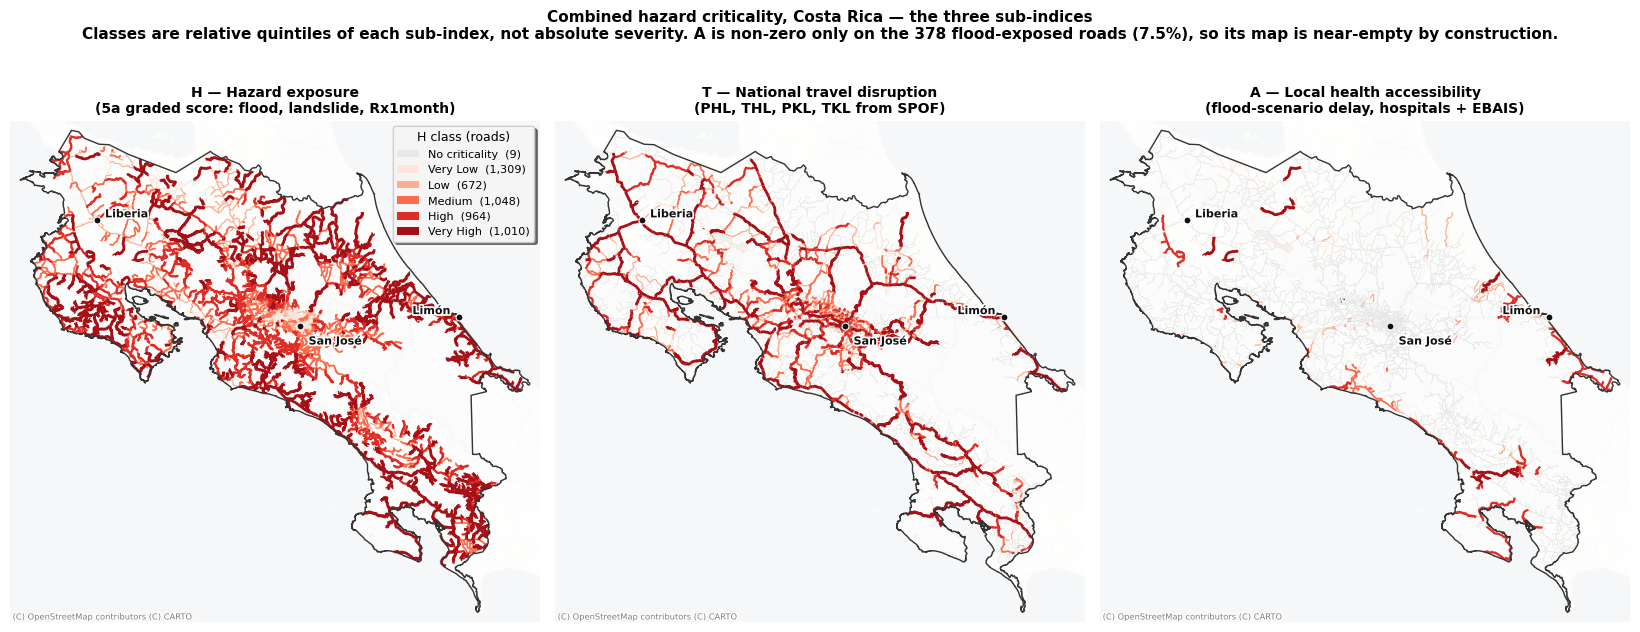

In [11]:

# ---- 8a. The three sub-indices side by side ------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16.5, 6.5))
draw_classes(axes[0], "H_class", "H — Hazard exposure\n(5a graded score: flood, landslide, Rx1month)")
draw_classes(axes[1], "T_class", "T — National travel disruption\n(PHL, THL, PKL, TKL from SPOF)")
draw_classes(axes[2], "A_class", "A — Local health accessibility\n(flood-scenario delay, hospitals + EBAIS)")
class_legend(axes[0], "H_class", title="H class (roads)", fontsize=8, title_fontsize=9)
fig.suptitle(
    "Combined hazard criticality, Costa Rica — the three sub-indices\n"
    "Classes are relative quintiles of each sub-index, not absolute severity. "
    "A is non-zero only on the 378 flood-exposed roads (7.5%), so its map is near-empty by construction.",
    fontsize=11, fontweight="bold", y=1.02,
)
plt.tight_layout()
save_fig(fig, "hazard_criticality_HTA_3panel_CR.png")
plt.show()

saved  figures/combined_hazard_criticality_CR.png


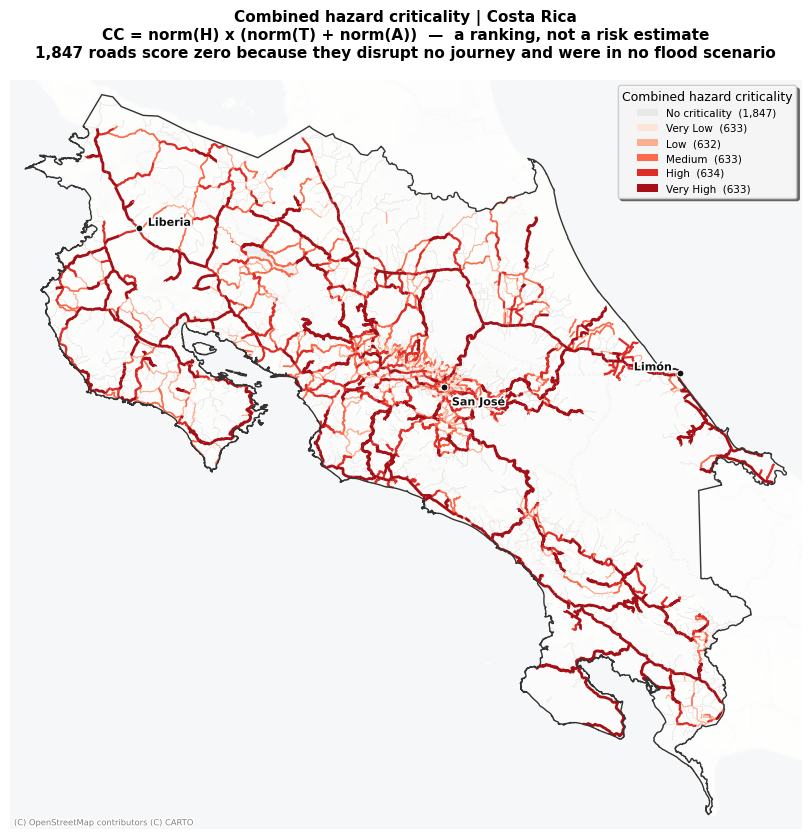

In [12]:

# ---- 8b. The combined index ----------------------------------------------
fig, ax = plt.subplots(figsize=(9.5, 8.5))
draw_classes(ax, "CC_class", "")
class_legend(ax, "CC_class", title="Combined hazard criticality")
ax.set_title(
    "Combined hazard criticality | Costa Rica\n"
    "CC = norm(H) x (norm(T) + norm(A))  —  a ranking, not a risk estimate\n"
    f"{int((gdf['CC'] == 0).sum()):,} roads score zero because they disrupt no journey "
    "and were in no flood scenario",
    fontsize=11, fontweight="bold",
)
plt.tight_layout()
save_fig(fig, "combined_hazard_criticality_CR.png")
plt.show()

saved  figures/hazard_criticality_metric_support_CR.png


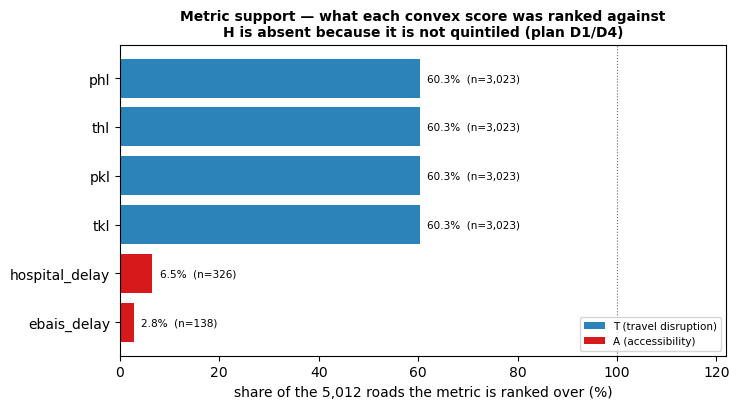

In [13]:

# ---- 8c. Metric support --------------------------------------------------
fig, ax1 = plt.subplots(figsize=(7.5, 4.2))
colours = ["#2b83ba" if sub == "T" else "#d7191c" for sub in support["sub_index"]]
ax1.barh(support["metric"], support["pct_network"], color=colours)
ax1.axvline(100, color="#666", lw=0.8, ls=":")
ax1.set_xlabel("share of the 5,012 roads the metric is ranked over (%)")
ax1.set_title("Metric support — what each convex score was ranked against\n"
              "H is absent because it is not quintiled (plan D1/D4)",
              fontsize=10, fontweight="bold")
ax1.invert_yaxis()
for y, (pct, n) in enumerate(zip(support["pct_network"], support["ranked_roads"])):
    ax1.text(pct + 1.5, y, f"{pct:.1f}%  (n={n:,})", va="center", fontsize=7.5)
ax1.set_xlim(0, 122)
ax1.legend(handles=[Patch(facecolor="#2b83ba", label="T (travel disruption)"),
                    Patch(facecolor="#d7191c", label="A (accessibility)")],
           fontsize=7.5, loc="lower right")
plt.tight_layout()
save_fig(fig, "hazard_criticality_metric_support_CR.png")
plt.show()

saved  figures/hazard_criticality_variants_CR.png


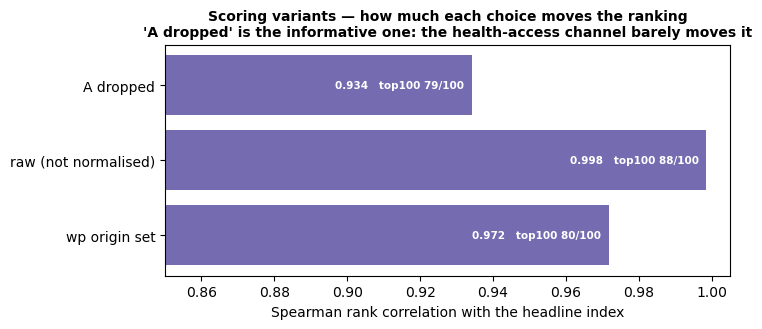

In [14]:

# ---- 8d. Scoring-variant spread -----------------------------------------
fig, ax2 = plt.subplots(figsize=(7.5, 3.4))
ax2.barh(sens["variant"], sens["spearman"], color="#756bb1")
ax2.set_xlim(0.85, 1.005)
ax2.set_xlabel("Spearman rank correlation with the headline index")
ax2.set_title("Scoring variants — how much each choice moves the ranking\n"
              "'A dropped' is the informative one: the health-access channel barely moves it",
              fontsize=10, fontweight="bold")
ax2.invert_yaxis()
for y, (rho, t100) in enumerate(zip(sens["spearman"], sens["top100"])):
    ax2.text(rho - 0.002, y, f"{rho:.3f}   top100 {t100}/100",
             va="center", ha="right", fontsize=7.5, color="white", fontweight="bold")
plt.tight_layout()
save_fig(fig, "hazard_criticality_variants_CR.png")
plt.show()

## 9. The IDS quintile crossing

Deferred here from 5a (its plan decision D4): 5a produces the hazard × criticality table, and the
socioeconomic attribution is applied downstream. This is that step, and it has no counterpart in the
Serbia notebook.

Two rules inherited from 2b, both non-negotiable:

- **Every quintile share is printed against its population share.** IDS quintiles are equal-count in
  *districts* (98 each), not in people — Q-I holds 11.2 % of the population and Q-IV 28.7 % — so a
  raw share comparison is partly mechanical.
- **IDS is a development ranking, not an income measure** (see `MD/district_income_shares_CR.md`).
  "Q-I" means lowest *Índice de Desarrollo Social*, not poorest by income.

The population denominator is computed with a plain code join on `CÓDIGO_DTA`, which leaves 0.22 % of
population unclassified. 2b resolves two of those three localities with a spatial fallback, reaching
0.09 %; the 0.13 % difference does not move any share below.

### Attributing the A sub-index to quintiles

The panel carries a fourth bar for **A**, but A is the weakest of the four and the reason is
worth stating before the number is read.

PHL decomposes naturally: 2b splits it by each road's OD-flow composition, and
`phl_q == phl × share_q` exactly. **A has no such decomposition** — it is a per-road scalar (a
basin mean delay), not a flow. It is therefore attributed with the *same* `share_q` weights, which
carries two limits:

1. **The weights describe who travels, not whose health access is lost.** Those populations
   overlap but are not the same, so the A bar is a proxy rather than a measurement.
2. **Roads with no attributable OD flow enter no quintile at all**, and they carry a large share of
   A — because A is non-zero on many roads that disrupt no modelled journey. The notebook prints
   the realised coverage; it is around half.

**The direct attribution is blocked upstream, not by method.** 5b's `origins_affected.parquet`
stamps a constant `origin_id` (`'19010101'`) on all 191 rows of the `loc` arm, so per-origin detail
cannot be traced back to a locality or district. `population`, `delta_h` and the person-hour totals
are all row-correct and nothing downstream joins on `origin_id`, so **no published 5b or 5c number
is affected** — but it does prevent computing "person-hours added by IDS quintile" straight from the
affected origins, which is what this bar should ideally show. The `wp` arm has valid per-cell ids.
Carried as a `TODO-fix` at the point of use below.

In [15]:

# ---- population per quintile: the denominator ----------------------------
ids = gpd.read_file(ids_shp)
localities = gpd.read_file(localities_shp)
joined = localities.merge(
    ids[["CODIGO_DTA", "QUINTIL"]],
    left_on="CÓDIGO_DTA", right_on="CODIGO_DTA", how="left",
)
pop_by_q = joined.groupby(joined["QUINTIL"].fillna("unclassified"))["INEC_PROY"].sum()
pop_total = pop_by_q.sum()
pop_share = (pop_by_q.reindex(QUINTIL_ORDER) / pop_total * 100).to_numpy()

print(f"population total      : {pop_total:,.0f}")
print(f"unclassified          : {pop_by_q.get('unclassified', 0):,.0f} "
      f"({100 * pop_by_q.get('unclassified', 0) / pop_total:.2f}%)")
print("\ndistricts per quintile:", ids["QUINTIL"].value_counts().reindex(QUINTIL_ORDER).to_dict())

# ---- cross CC with 2b's quintile attribution -----------------------------
cross = gdf[["physical_edge_id", "CC", "CC_class", "road_length", "A"]].merge(
    socio[["physical_edge_id", "dominant_quintile"]
          + [f"phl_{q}" for q in QCOLS] + [f"share_{q}" for q in QCOLS] + ["share_qNA"]],
    on="physical_edge_id", how="left", validate="1:1",
)

decile_n = int(round(0.10 * len(cross)))
top_decile = cross.nlargest(decile_n, "CC")
phl_top = np.array([top_decile[f"phl_{q}"].sum() for q in QCOLS])
phl_all = np.array([cross[f"phl_{q}"].sum() for q in QCOLS])

# ---- attributing the A sub-index to quintiles ----------------------------
# A has no quintile decomposition of its own. PHL does: 2b splits it by multiplying each
# road's PHL with its OD-flow composition, and phl_q == phl x share_q exactly (verified).
# Those weights are the only route available for A today, so A is split the same way.
#
# TWO limits, both material, so they are printed rather than buried:
#   1. share_q describes who TRAVELS on the road; A measures whose HEALTH ACCESS is lost.
#      The two populations overlap but are not the same, so this is a proxy.
#   2. Roads with no attributable OD flow enter no quintile at all -- and they are a large
#      share of A, because A is non-zero on many roads that disrupt no modelled journey.
#
# TODO-fix: the direct attribution is blocked upstream, not by method. 5b's
# origins_affected.parquet stamps a CONSTANT origin_id ('19010101') on all 191 rows of the
# `loc` arm, so per-origin detail cannot be traced to a locality or district. population /
# delta_h / person-hours are all row-correct and nothing downstream joins on origin_id, so
# no published 5b or 5c number is affected -- but it does block computing "person-hours
# added by IDS quintile" directly from the affected origins, which is what this bar should
# ideally show. The `wp` arm has valid per-cell ids. Measured 2026-09-18.
flow = cross[[f"share_{q}" for q in QCOLS]].fillna(0.0)
flow_total = flow.sum(axis=1) + cross["share_qNA"].fillna(0.0)
A_q = np.array([(cross["A"] * flow[f"share_{q}"]).sum() for q in QCOLS])

a_pos = cross["A"] > 0
a_noflow = a_pos & (flow_total < 1e-9)
A_COVERAGE = 100 * (1 - cross.loc[a_noflow, "A"].sum() / cross.loc[a_pos, "A"].sum())

equity = pd.DataFrame({
    "quintile": QNAMES,
    "pop_share_pct": pop_share,
    "phl_share_all_pct": 100 * phl_all / phl_all.sum(),
    "phl_share_top_decile_pct": 100 * phl_top / phl_top.sum(),
    "A_share_pct": 100 * A_q / A_q.sum(),
})
equity["ratio_phl_top_to_pop"] = equity["phl_share_top_decile_pct"] / equity["pop_share_pct"]
equity["ratio_A_to_pop"] = equity["A_share_pct"] / equity["pop_share_pct"]

print(f"\nDisruption by IDS quintile - whole network, the top {decile_n} roads by CC, "
      f"and the A sub-index:\n")
print(equity.to_string(index=False, float_format=lambda v: f"{v:6.2f}"))

print(f"\nA-attribution coverage: {A_COVERAGE:.1f}% of the A total is flow-attributable.")
print(f"  {int(a_noflow.sum()):,} of {int(a_pos.sum()):,} roads with A > 0 "
      f"({100 * a_noflow.sum() / a_pos.sum():.1f}%) carry no OD flow at all, so they enter no")
print(f"  quintile and {100 - A_COVERAGE:.1f}% of the A signal is absent from the A column.")
print("  Those are exactly the roads with A > 0 and T = 0 -- remote roads that sit in a flood")
print("  scenario but disrupt no modelled journey. The A column therefore describes the")
print("  flow-attributable part of A, and the missing part is not a random sample of it.")

population total      : 5,167,278
unclassified          : 11,220 (0.22%)

districts per quintile: {'I': 98, 'II': 98, 'III': 98, 'IV': 98, 'V': 98}

Disruption by IDS quintile - whole network, the top 501 roads by CC, and the A sub-index:

         quintile  pop_share_pct  phl_share_all_pct  phl_share_top_decile_pct  A_share_pct  ratio_phl_top_to_pop  ratio_A_to_pop
 Q-I (lowest IDS)          11.23              26.06                     32.26        33.52                  2.87            2.98
             Q-II          14.31              15.11                     16.46        22.55                  1.15            1.58
            Q-III          20.73              20.63                     21.80        17.97                  1.05            0.87
             Q-IV          28.65              20.15                     16.78        15.20                  0.59            0.53
Q-V (highest IDS)          24.85              18.05                     12.70        10.77                  0.51   

In [16]:

print("CC class x dominant quintile (2b's majority-share attribution):\n")
tab = pd.crosstab(cross["CC_class"], cross["dominant_quintile"]).reindex(CLASS_ORDER).fillna(0).astype(int)
print(tab.to_string())
print("\n'none' = the road carries no attributable OD flow at all (2b), which is the same")
print("1,843-road set that scores CC = 0. It is kept, never dropped.")

r1, r5 = equity.loc[0, "ratio_phl_top_to_pop"], equity.loc[4, "ratio_phl_top_to_pop"]
print(f"\nHEADLINE: on the most critical decile of roads, Q-I districts bear "
      f"{equity.loc[0, 'phl_share_top_decile_pct']:.1f}% of passenger hours lost")
print(f"          against {equity.loc[0, 'pop_share_pct']:.1f}% of the population "
      f"-- a ratio of {r1:.2f}.")
print(f"          Q-V bears {equity.loc[4, 'phl_share_top_decile_pct']:.1f}% "
      f"against {equity.loc[4, 'pop_share_pct']:.1f}% -- a ratio of {r5:.2f}.")
print(f"          The gradient is monotone across the five quintiles and it steepens as CC")
print(f"          rises: Very High CC is dominated by Q-I/Q-II roads, Very Low by Q-IV/Q-V.")
print(f"\n          The A sub-index runs the SAME WAY BUT STEEPER: Q-I takes "
      f"{equity.loc[0, 'A_share_pct']:.1f}% of the attributable A against "
      f"{equity.loc[0, 'pop_share_pct']:.1f}% of population")
print(f"          (ratio {equity.loc[0, 'ratio_A_to_pop']:.2f}), while Q-V takes "
      f"{equity.loc[4, 'A_share_pct']:.1f}% (ratio {equity.loc[4, 'ratio_A_to_pop']:.2f}). "
      f"So the health-access channel")
print(f"          is MORE regressive than the travel channel -- on {A_COVERAGE:.0f}% coverage, "
      f"which is the caveat")
print(f"          that has to travel with it.")

print("\nCaveat that travels with this: PHL is traffic-weighted, so a quintile's share reflects")
print("both how much its people travel and how exposed their roads are. It is not a welfare")
print("measure, and IDS is a development ranking rather than an income one.")

CC class x dominant quintile (2b's majority-share attribution):

dominant_quintile  none   q1   q2   q3   q4   q5
CC_class                                        
No criticality     1843    0    4    0    0    0
Very Low             10   35   32   66  213  277
Low                  25  120   96  107  157  127
Medium               30  108   93  105  183  114
High                 41  127  118  118  174   56
Very High            40  206  184  114   85    4

'none' = the road carries no attributable OD flow at all (2b), which is the same
1,843-road set that scores CC = 0. It is kept, never dropped.

HEADLINE: on the most critical decile of roads, Q-I districts bear 32.3% of passenger hours lost
          against 11.2% of the population -- a ratio of 2.87.
          Q-V bears 12.7% against 24.9% -- a ratio of 0.51.
          The gradient is monotone across the five quintiles and it steepens as CC
          rises: Very High CC is dominated by Q-I/Q-II roads, Very Low by Q-IV/Q-V.

          T

saved  figures/hazard_criticality_by_IDS_quintile_CR.png


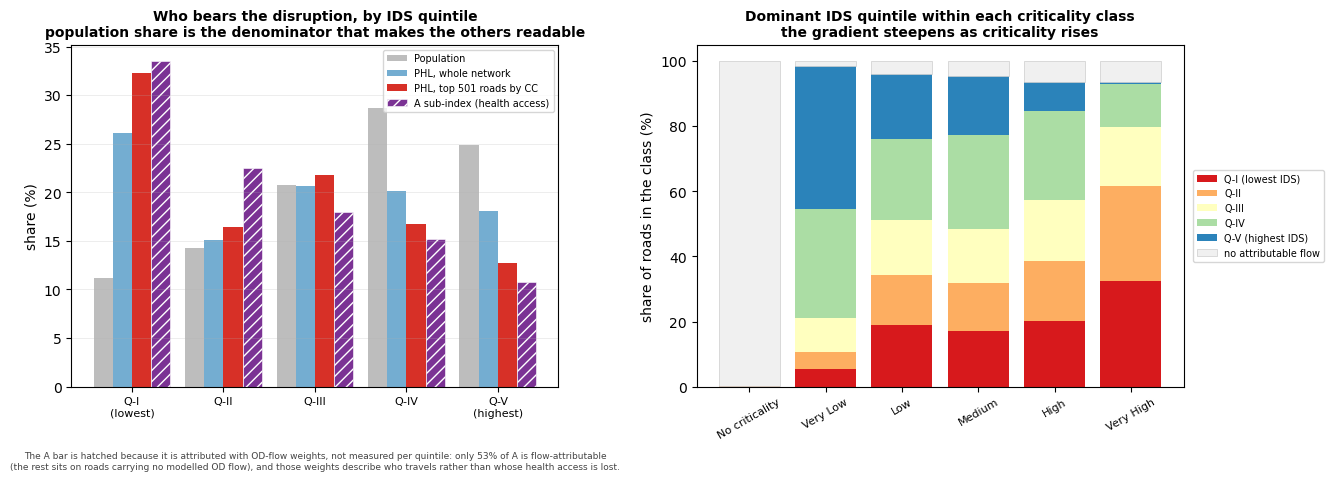

In [17]:

# ---- the equity figure ---------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.0))

x = np.arange(len(QNAMES))
w = 0.21
ax1.bar(x - 1.5 * w, equity["pop_share_pct"], w, label="Population", color="#bdbdbd")
ax1.bar(x - 0.5 * w, equity["phl_share_all_pct"], w,
        label="PHL, whole network", color="#74add1")
ax1.bar(x + 0.5 * w, equity["phl_share_top_decile_pct"], w,
        label=f"PHL, top {decile_n} roads by CC", color="#d73027")
# Hatched, because A is ATTRIBUTED with OD-flow weights rather than measured per quintile.
ax1.bar(x + 1.5 * w, equity["A_share_pct"], w,
        label="A sub-index (health access)", color="#7b3294",
        hatch="///", edgecolor="white", linewidth=0.4)
ax1.set_xticks(x)
ax1.set_xticklabels(["Q-I\n(lowest)", "Q-II", "Q-III", "Q-IV", "Q-V\n(highest)"], fontsize=8)
ax1.set_ylabel("share (%)")
ax1.set_title("Who bears the disruption, by IDS quintile\n"
              "population share is the denominator that makes the others readable",
              fontsize=10, fontweight="bold")
ax1.legend(fontsize=7)
ax1.grid(axis="y", lw=0.4, alpha=0.4)
ax1.text(0.5, -0.19,
         f"The A bar is hatched because it is attributed with OD-flow weights, not measured "
         f"per quintile: only {A_COVERAGE:.0f}% of A is flow-attributable\n"
         f"(the rest sits on roads carrying no modelled OD flow), and those weights describe "
         f"who travels rather than whose health access is lost.",
         transform=ax1.transAxes, ha="center", va="top", fontsize=6.5, color="#444444")

shares = tab.reindex(columns=QCOLS + ["none"]).fillna(0)
shares = shares.div(shares.sum(axis=1), axis=0) * 100
bottom = np.zeros(len(shares))
for q, name, colour in zip(QCOLS, QNAMES, QCOLORS):
    ax2.bar(shares.index, shares[q], bottom=bottom, label=name, color=colour)
    bottom += shares[q].to_numpy()
ax2.bar(shares.index, shares["none"], bottom=bottom, label="no attributable flow",
        color="#f0f0f0", edgecolor="#cccccc", lw=0.5)
ax2.set_ylabel("share of roads in the class (%)")
ax2.set_title("Dominant IDS quintile within each criticality class\n"
              "the gradient steepens as criticality rises",
              fontsize=10, fontweight="bold")
ax2.tick_params(axis="x", labelrotation=30, labelsize=8)
ax2.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5))

plt.tight_layout()
save_fig(fig, "hazard_criticality_by_IDS_quintile_CR.png")
plt.show()

## 10. Statistics by road class

Serbia reports by `kategorija` (IA / IB / IM / IIA / IIB). CR's equivalent is `CLASE`
(Primaria / Secundaria / Terciaria / Local / Sin clasificar), which is a functional class rather
than an administrative tier, so the Serbia high-tier/low-tier split does not carry over.

In [18]:

by_class = gdf.groupby("CLASE").agg(
    roads=("physical_edge_id", "size"),
    km=("road_length", "sum"),
    H_mean=("H", "mean"),
    T_mean=("T", "mean"),
    A_mean=("A", "mean"),
    CC_mean=("CC", "mean"),
    CC_max=("CC", "max"),
).sort_values("CC_mean", ascending=False)
by_class["km_share_pct"] = 100 * by_class["km"] / NETWORK_KM
by_class["pct_high_or_very_high"] = (
    gdf.assign(hi=gdf["CC_class"].isin(["High", "Very High"]))
       .groupby("CLASE")["hi"].mean().reindex(by_class.index) * 100
)
print("Combined hazard criticality by road class:\n")
print(by_class.to_string(float_format=lambda v: f"{v:,.2f}"))

print("\n\nTop 15 roads by combined hazard criticality:\n")
top15 = gdf.nlargest(15, "CC")[[
    "physical_edge_id", "NOMBRE", "CLASE", "road_length", "total_aadt",
    "hazard_score", "H", "T", "A", "CC", "CC_class",
]]
print(top15.to_string(index=False, float_format=lambda v: f"{v:,.2f}"))

n_hi = int(gdf["CC_class"].isin(["High", "Very High"]).sum())
print(f"\nKEY: {TOTAL_ROADS:,} physical roads scored; {n_hi:,} ({100 * n_hi / TOTAL_ROADS:.1f}%) "
      f"High or Very High combined criticality.")
print(f"     {int(gdf['a_evaluated'].sum()):,} of them carry a measured accessibility term; "
      f"the rest score A = 0 structurally.")

Combined hazard criticality by road class:

                roads       km  H_mean  T_mean  A_mean  CC_mean  CC_max  km_share_pct  pct_high_or_very_high
CLASE                                                                                                       
Primaria          717 2,030.76    0.32   27.27    0.72     0.26    1.42         13.71                  68.62
Secundaria       1247 2,755.95    0.28   12.18    0.18     0.11    1.33         18.61                  32.56
Terciaria         726 3,101.87    0.39    6.13    0.30     0.07    0.80         20.94                  23.42
Sin clasificar    123   475.02    0.40    4.17    0.33     0.05    0.70          3.21                  17.07
Local            2199 6,446.96    0.33    2.30    0.32     0.03    1.40         43.53                   8.09


Top 15 roads by combined hazard criticality:

 physical_edge_id                NOMBRE      CLASE  road_length  total_aadt  hazard_score    H     T     A   CC  CC_class
             1214   Rut

## 11. Outputs

One GeoPackage in EPSG:8908 with **all 5,012 roads retained** — nothing filtered, so the layer is
usable as a denominator. No File GDB, no `.lyrx` (`arcpy` is absent, and Serbia's own run never
generated them either), no parquet mirror.

The workbook (plan D8) is the artefact a non-GIS reader opens, so the Metric Descriptions sheet
carries the caveats rather than burying them in this notebook.

In [19]:

ID_COLS = ["physical_edge_id", "ID_TRAMO", "ID_RUTA", "NOMBRE", "CLASE", "ADMIN",
           "road_length", "speed", "total_aadt", "aadt_imputed"]
HAZARD_COLS = ["flood_value", "flood_min_rp", "flood_aep", "flood_share_gt0p25",
               "flood_depth_implausible", "landslide_value", "precip_rx1month_value",
               "n_water_crossings", "has_temporary_structure", "flood_correction_applied",
               "flood_band", "landslide_band", "rain_band", "hazard_score"]
TRAVEL_COLS = ["vhl", "vkl"] + TRAVEL_METRICS + [f"{m}_cv" for m in TRAVEL_METRICS] + \
              ["pct_isolated", "pct_unaffected", "pct_delayed"]
ACCESS_COLS = ACCESS_METRICS + [f"{m}_cv" for m in ACCESS_METRICS] + \
              ["a_evaluated", "n_origins_hospitals", "n_origins_ebais"]
SCORE_COLS = ["H", "T", "A", "H_norm", "T_norm", "A_norm", "CC",
              "H_class", "T_class", "A_class", "CC_class"]

keep = ID_COLS + HAZARD_COLS + TRAVEL_COLS + ACCESS_COLS + SCORE_COLS
keep = [c for c in keep if c in gdf.columns]

out = gdf[keep + ["geometry"]].copy()
out["origin_set_for_A"] = ORIGIN_SET          # provenance, so no consumer has to infer it
out["index_definition"] = "CC = norm(H) * (norm(T) + norm(A)); H = 5a hazard_score"
out = out.sort_values("CC", ascending=False).reset_index(drop=True)

# GeoPackage has no boolean type and object columns confuse the driver.
for col in out.columns:
    if col == "geometry":
        continue
    if out[col].dtype == bool:
        out[col] = out[col].astype(int)
    elif out[col].dtype.name in ("category", "object"):
        out[col] = out[col].astype("string")

out.to_crs(WORKING_EPSG).to_file(out_gpkg, layer="criticality", driver="GPKG")
print(f"saved  {out_gpkg.relative_to(BASE_DIR)}")
print(f"       layer 'criticality': {len(out):,} roads x {len(out.columns)} cols, EPSG:{WORKING_EPSG}")
assert len(out) == TOTAL_ROADS, "rows lost on export"

saved  intermediate_results/gpkg/travel_disruptions/combined_hazard_criticality.gpkg
       layer 'criticality': 5,012 roads x 58 cols, EPSG:8908


In [20]:

# ---- the workbook --------------------------------------------------------
descriptions = pd.DataFrame(
    [
        ("physical_edge_id", "Physical road identifier (both directions of one road)", "-"),
        ("ID_TRAMO", "Source road-section identifier", "-"),
        ("NOMBRE", "Road name", "-"),
        ("CLASE", "Functional road class (Primaria / Secundaria / Terciaria / Local)", "-"),
        ("road_length", "Road length", "km"),
        ("total_aadt", "Annual average daily traffic", "vehicles/day"),
        ("", "--- HAZARD (H) ---", ""),
        ("flood_value", "Maximum JRC RP100 inundation depth sampled along the road. NOTE reduced "
                        "with max, so the median exposed road is wet on only ~14% of its length", "m"),
        ("flood_min_rp", "Smallest return period at which depth exceeds 0.25 m; blank = never up to RP500", "years"),
        ("flood_band", "Flood exceedance band, 0 (never) to 7 (floods at RP10)", "0-7"),
        ("landslide_value", "NASA LHASA landslide susceptibility class. Susceptibility, not an "
                            "observed inventory, and not validated against CR failures", "0-5"),
        ("landslide_band", "Landslide class used directly as an ordinal", "0-5"),
        ("precip_rx1month_value", "CHIRPS Rx1month 20-year return level. Substitutes for Rx1day: a wet "
                                  "month of moderate days scores like one with a single extreme day", "mm"),
        ("rain_band", "Rainfall return-level band", "0-3"),
        ("hazard_score", "H. Mean of the three bands, each divided by its own maximum", "0-1"),
        ("", "--- TRAVEL DISRUPTION (T) ---", ""),
        ("phl", "Passenger hours lost if this road is closed (SPOF, traffic-weighted)", "passenger-hours/day"),
        ("thl", "Tonne hours lost if this road is closed", "tonne-hours/day"),
        ("pkl", "Passenger km lost to rerouting", "passenger-km/day"),
        ("tkl", "Tonne km lost to rerouting", "tonne-km/day"),
        ("*_cv", "Convex score of the metric: quintile 1-5 mapped through "
                 "{1:0.5, 2:1, 3:2, 4:5, 5:10}. Q5 counts 20x Q1", "0-10"),
        ("T", "Sum of the four travel convex scores", "0-40"),
        ("", "--- LOCAL ACCESSIBILITY (A) ---", ""),
        ("hospital_delay", "Mean positive delay to the nearest hospital under the flood scenario that "
                           "removed this road. INCLUDES origins cut off entirely and charged the 7 h "
                           "isolation penalty (31.8% of affected rows), and is a BASIN mean replicated "
                           "onto every road in that basin. Not an ordinary travel time", "hours"),
        ("ebais_delay", "As above, to the nearest EBAIS. 52% of population sits at 0 min from an EBAIS, "
                        "so this sector is structurally weak -- see notebook 5b", "hours"),
        ("a_evaluated", "1 = the road was in a flood scenario and A was measured (378 roads). "
                        "0 = never evaluated, so A = 0 structurally rather than by measurement", "0/1"),
        ("A", "Sum of the two accessibility convex scores", "0-20"),
        ("", "--- COMBINED ---", ""),
        ("H_norm / T_norm / A_norm", "Each sub-index min-max normalised to [0, 1]. norm(H) is an "
                                     "identity because hazard_score already spans [0, 1]", "0-1"),
        ("CC", "Combined hazard criticality = norm(H) x (norm(T) + norm(A))", "0-2"),
        ("*_class", "Relative quintile label of the sub-index. NOT absolute severity: 'Very High' "
                    "always holds about a fifth of the positive values. Not comparable across runs", "-"),
    ],
    columns=["Column", "Description", "Unit"],
)

caveats = pd.DataFrame(
    [
        ("Not risk", "Roads are screened one at a time against hazard footprints. No fragility "
                     "curve, no closure probability, no duration, no expected annual loss."),
        ("Not 'climate'", "All three CR hazards are present-day. CR has no climate-projection "
                          "data, so the Serbia original's 'climate criticality' name is dropped."),
        ("A is flood-conditional", f"A is non-zero only on flood-exposed roads. "
                                   f"Spearman(A, flood depth) = "
                                   f"{spearmanr(gdf['A'], gdf['flood_value'].fillna(0)).statistic:.2f}, "
                                   f"Spearman(H, A) = {spearmanr(gdf['H'], gdf['A']).statistic:.2f} "
                                   f"against 0.03 in Serbia. Read CC as H x T with A at the margin."),
        ("A contributes little", f"Dropping A entirely gives Spearman "
                                 f"{sens.loc[sens['variant'] == 'A dropped', 'spearman'].iloc[0]:.3f} "
                                 f"with the headline index."),
        ("H scored differently from T and A", "H uses 5a's per-layer bands; T and A are quintiled "
                                              "over their non-zero values. Metric support ranges "
                                              "from 6.5% to 99.8% of the network."),
        ("Flood depth is length-biased", "Sampling reduces with max, so one deep cell condemns a "
                                         "whole road. Maximum observed 30.7 m is a river "
                                         "cross-section, not a road surface."),
        ("0.25 m threshold", "Inherited from the Serbia pipeline, derived nowhere."),
        ("Zero is not one thing", "1,843 roads score CC = 0 because they disrupt no journey and "
                                  "were in no scenario. 52 more have a measured A of exactly zero. "
                                  "a_evaluated separates the two."),
        ("IDS is not income", "MIDEPLAN IDS is a development ranking. Quintiles are equal-count in "
                              "districts, not in people, so shares need the population denominator."),
    ],
    columns=["Caveat", "Detail"],
)

attrs = out.drop(columns="geometry")
sheets = {
    "Overview": attrs[[c for c in ID_COLS + SCORE_COLS if c in attrs.columns]],
    "Hazard Exposure": attrs[[c for c in ID_COLS[:6] + HAZARD_COLS + ["H", "H_class"] if c in attrs.columns]],
    "Travel Disruption": attrs[[c for c in ID_COLS[:6] + TRAVEL_COLS + ["T", "T_class"] if c in attrs.columns]],
    "Local Accessibility": attrs[[c for c in ID_COLS[:6] + ACCESS_COLS + ["A", "A_class"] if c in attrs.columns]],
    "IDS Equity": equity,
    "Criticality x Quintile": tab.reset_index(),
    "Scoring Variants": sens,
    "Metric Support": support,
    "Metric Descriptions": descriptions,
    "Caveats": caveats,
}

with pd.ExcelWriter(out_xlsx, engine="openpyxl") as writer:
    for name, frame in sheets.items():
        frame.to_excel(writer, sheet_name=name[:31], index=False)

# ---- formatting ---------------------------------------------------------
from openpyxl import load_workbook
from openpyxl.styles import Alignment, Font, PatternFill
from openpyxl.utils import get_column_letter

CLASS_FILL = {
    "No criticality": "E8E8E8", "Very Low": "FEE5D9", "Low": "FCAE91",
    "Medium": "FB6A4A", "High": "DE2D26", "Very High": "A50F15",
}
wb = load_workbook(out_xlsx)
header_font = Font(bold=True, color="FFFFFF")
header_fill = PatternFill("solid", fgColor="31698A")
for ws in wb.worksheets:
    for cell in ws[1]:
        cell.font = header_font
        cell.fill = header_fill
        cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
    ws.freeze_panes = "A2"
    class_cols = [c[0].column for c in ws.iter_cols(min_row=1, max_row=1)
                  if isinstance(c[0].value, str) and c[0].value.endswith("_class")]
    for col in ws.iter_cols(min_row=1, max_row=1):
        letter = get_column_letter(col[0].column)
        header = str(col[0].value or "")
        ws.column_dimensions[letter].width = min(max(12, len(header) + 3), 70)
    if ws.title in ("Metric Descriptions", "Caveats"):
        ws.column_dimensions["B"].width = 96
        for row in ws.iter_rows(min_row=2):
            row[1].alignment = Alignment(wrap_text=True, vertical="top")
    for col_idx in class_cols:
        for row in ws.iter_rows(min_row=2, min_col=col_idx, max_col=col_idx):
            fill = CLASS_FILL.get(row[0].value)
            if fill:
                row[0].fill = PatternFill("solid", fgColor=fill)
wb.save(out_xlsx)

print(f"saved  {out_xlsx.relative_to(BASE_DIR)}")
for name, frame in sheets.items():
    print(f"       {name:24s} {len(frame):5,d} rows x {len(frame.columns):2d} cols")

saved  intermediate_results/excel/Combined_Hazard_Criticality_CR.xlsx
       Overview                 5,012 rows x 21 cols
       Hazard Exposure          5,012 rows x 22 cols
       Travel Disruption        5,012 rows x 21 cols
       Local Accessibility      5,012 rows x 15 cols
       IDS Equity                   5 rows x  7 cols
       Criticality x Quintile       6 rows x  7 cols
       Scoring Variants             3 rows x  5 cols
       Metric Support               6 rows x  7 cols
       Metric Descriptions         31 rows x  3 cols
       Caveats                      9 rows x  2 cols


## 12. Run reconciliation

In [21]:

print("=" * 74)
print("RUN RECONCILIATION")
print("=" * 74)
print(f"Physical roads in       : {TOTAL_ROADS:,}")
print(f"Physical roads out      : {len(out):,}")
print(f"Network length          : {NETWORK_KM:,.0f} km")
print(f"Roads dropped           : {TOTAL_ROADS - len(out)}  (must be 0 -- nothing is filtered)")
print()
print(f"H source                : 5a hazard_score (flood + landslide + Rx1month bands)")
print(f"T metrics               : {', '.join(TRAVEL_METRICS)}  (ceiling 40)")
print(f"A metrics               : {', '.join(ACCESS_METRICS)}  (ceiling 20, origin set '{ORIGIN_SET}')")
print(f"Index                   : CC = norm(H) x (norm(T) + norm(A))")
print()
print(f"Roads with H > 0        : {int((gdf['H'] > 0).sum()):,}")
print(f"Roads with T > 0        : {int((gdf['T'] > 0).sum()):,}")
print(f"Roads with A > 0        : {int((gdf['A'] > 0).sum()):,}   "
      f"(evaluated: {int(gdf['a_evaluated'].sum()):,})")
print(f"Roads with CC = 0       : {int((gdf['CC'] == 0).sum()):,}   "
      f"({100 * (gdf['CC'] == 0).mean():.1f}% -- structural, see section 5)")
print()
print(f"Figures written         : 5")
print(f"GeoPackage              : {out_gpkg.relative_to(BASE_DIR)}")
print(f"Workbook                : {out_xlsx.relative_to(BASE_DIR)}")

assert len(out) == TOTAL_ROADS
assert gdf["CC"].notna().all(), "NaN in the combined index"
assert gdf["CC_class"].notna().all(), "unclassified roads"
print("\nSTATUS: COMPLETE")

RUN RECONCILIATION
Physical roads in       : 5,012
Physical roads out      : 5,012
Network length          : 14,811 km
Roads dropped           : 0  (must be 0 -- nothing is filtered)

H source                : 5a hazard_score (flood + landslide + Rx1month bands)
T metrics               : phl, thl, pkl, tkl  (ceiling 40)
A metrics               : hospital_delay, ebais_delay  (ceiling 20, origin set 'loc')
Index                   : CC = norm(H) x (norm(T) + norm(A))

Roads with H > 0        : 5,003
Roads with T > 0        : 3,023
Roads with A > 0        : 326   (evaluated: 378)
Roads with CC = 0       : 1,847   (36.9% -- structural, see section 5)

Figures written         : 5
GeoPackage              : intermediate_results/gpkg/travel_disruptions/combined_hazard_criticality.gpkg
Workbook                : intermediate_results/excel/Combined_Hazard_Criticality_CR.xlsx

STATUS: COMPLETE
